# CSE366 – Submission 3: Custom CNN from Scratch
**Project:** PCB-LiteX – PCB Defect Classification  
**Dataset:** PCB-Defect (Mendeley Data) – 6 defect classes

## What the roadmap asks for in Submission 3
| Requirement | Where it is done |
|---|---|
| Multiple convolutional and pooling layers, ending with a fully connected layer | Custom CNN, Section 5 |
| ReLU activations and batch normalization | Every conv layer is followed by BatchNorm + ReLU (Section 5) |
| Proper preprocessing and data augmentation | Resize + normalise + flips + rotation + colour change (Section 3) |
| Consistent hyperparameters (batch size, optimizer, learning rate, etc.) | All set once in one table / one cell (Section 0) |
| Monitor training **and** validation loss to prevent overfitting | Loss printed and plotted every epoch (Sections 6 and 8) |
| Early stopping, minimum 5 epochs | Section 6 |
| Same metrics as Submission 2: accuracy, precision, recall, F1, confusion matrix, classification report, accuracy/loss curves, training and testing time | Sections 7, 8 and 9 |

The **same dataset and the same train / validation / test split** as Submission 2 are used (same seed), so the results can be compared fairly.

**Important:** use a GPU (Runtime → Change runtime type → T4 GPU) and run all cells before pushing to GitHub.

# 0. Import libraries and hyperparameters

In [1]:
import os
import json
import time
import copy
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Image.MAX_IMAGE_PIXELS = None   # the PCB board images are very large

# =====================================================
#   HYPERPARAMETERS (all in one place, never changed)
# =====================================================
SEED = 42              # same seed as Submission 2 -> same split
PATCH_SIZE = 224       # size of the saved patches (same as Submission 2)
INPUT_SIZE = 128       # size the CNN sees
CONTEXT = 3.0          # patch side = 3 x defect box side

BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
OPTIMIZER = "Adam"
DROPOUT = 0.5

MAX_EPOCHS = 60        # upper limit
MIN_EPOCHS = 5         # early stopping can NOT stop before this many epochs
PATIENCE = 10          # stop if validation loss does not improve for 10 epochs
# =====================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Training will be slow.")

RESULTS_DIR = Path("results_submission3")
RESULTS_DIR.mkdir(exist_ok=True)

Using device: cuda


| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 (halved when validation loss stops improving) |
| Weight decay | 0.0001 |
| Batch size | 32 |
| Loss function | Cross-entropy with class weights |
| Dropout (before the last layers) | 0.5 |
| Maximum epochs | 60 |
| Early stopping | patience 10 on validation loss, minimum 5 epochs |
| Input size | 128 × 128 × 3 |

# 1. Dataset
### 1.1 Download the dataset
Source: https://data.mendeley.com/datasets/vdj74sngvn/1  
If the automatic download does not work, we can download the ZIP file ourself and upload it when Colab asks.


In [2]:
DATA_DIR = Path("pcb_defect_data")
DATA_DIR.mkdir(exist_ok=True)
ZIP_PATH = DATA_DIR / "pcb_defect_v1.zip"
RAW_DIR = DATA_DIR / "raw"
URL = "https://data.mendeley.com/public-api/zip/vdj74sngvn/download/1"

if RAW_DIR.exists():
    print("Dataset already extracted.")
else:
    # step 1: try to download automatically
    try:
        print("Downloading dataset...")
        response = requests.get(URL, stream=True, timeout=180)
        response.raise_for_status()
        with open(ZIP_PATH, "wb") as f:
            for chunk in response.iter_content(1024 * 1024):
                f.write(chunk)
    except Exception as e:
        print("Automatic download failed:", e)

    # step 2: if it failed, ask the user to upload the ZIP file
    if not (ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH)):
        from google.colab import files
        print("Please upload the dataset ZIP file now.")
        uploaded = files.upload()
        uploaded_name = list(uploaded.keys())[0]
        os.replace(uploaded_name, ZIP_PATH)

    # step 3: extract the ZIP file
    RAW_DIR.mkdir()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

    # step 4: extract zip files inside the zip file (if there are any)
    for i in range(3):
        inner_zips = list(RAW_DIR.rglob("*.zip"))
        for inner in inner_zips:
            with zipfile.ZipFile(inner) as z:
                z.extractall(inner.parent)
            inner.unlink()
    print("Dataset extracted.")

Dataset extracted.


### 1.2 Read the annotation file (COCO format)

In [3]:
# find the COCO json file
coco = None
for json_path in RAW_DIR.rglob("*.json"):
    try:
        with open(json_path) as f:
            data = json.load(f)
        if "images" in data and "annotations" in data and "categories" in data:
            coco = data
            print("Annotation file:", json_path)
            break
    except Exception:
        continue
assert coco is not None, "No COCO annotation file found"

# find all image files
image_paths = {}
for p in RAW_DIR.rglob("*"):
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        image_paths[p.name] = p
print("Image files found:", len(image_paths))

# make lookup tables
category_names = {}
for c in coco["categories"]:
    category_names[c["id"]] = c["name"]

image_files = {}
for im in coco["images"]:
    image_files[im["id"]] = im["file_name"]

# put every defect (bounding box) in a table
rows = []
for a in coco["annotations"]:
    file_name = Path(image_files[a["image_id"]]).name
    if file_name not in image_paths:
        continue
    rows.append({
        "ann_id": a["id"],
        "board": a["image_id"],
        "label": category_names[a["category_id"]],
        "x": a["bbox"][0],
        "y": a["bbox"][1],
        "w": a["bbox"][2],
        "h": a["bbox"][3],
        "path": str(image_paths[file_name]),
    })
ann = pd.DataFrame(rows)

# only use classes that really have boxes (the dataset has one empty placeholder class)
CLASSES = sorted(ann["label"].unique())
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {}
for i in range(NUM_CLASSES):
    CLASS_TO_IDX[CLASSES[i]] = i

print("Classes:", CLASSES)
print("Number of boards:", ann["board"].nunique())
print("Number of defects:", len(ann))

Annotation file: pcb_defect_data/raw/PCB-Defect An Annotated Dataset for Surface Defect/PCB_Defect/annotation/_annotations.coco.json
Image files found: 230
Classes: ['missing_pad', 'mouse_bite', 'open_circuit', 'short', 'spur', 'spurious_copper']
Number of boards: 230
Number of defects: 1704


### 1.3 Cut one patch for every defect
Every defect box is cut out as a square image (patch) and gets its defect class as the label.
The patch is 3 times larger than the box, so the network can also see the copper around the defect.

In [4]:
PATCH_DIR = Path("patches")
META_FILE = PATCH_DIR / "meta.csv"

def crop_patch(board_image, x, y, w, h):
    """Cut a square patch around the defect box."""
    center_x = x + w / 2
    center_y = y + h / 2
    side = max(w, h) * CONTEXT
    side = max(side, 96)                                      # not too small
    side = min(side, board_image.width, board_image.height)   # not bigger than the board
    left = center_x - side / 2
    top = center_y - side / 2
    left = min(max(left, 0), board_image.width - side)        # keep the window inside the board
    top = min(max(top, 0), board_image.height - side)
    return board_image.crop((int(left), int(top), int(left + side), int(top + side)))

if META_FILE.exists():
    meta = pd.read_csv(META_FILE)
    print("Patches already created.")
else:
    for c in CLASSES:
        (PATCH_DIR / c).mkdir(parents=True, exist_ok=True)

    meta_rows = []
    for board_id, group in ann.groupby("board"):
        board_image = Image.open(group.iloc[0]["path"]).convert("RGB")
        for index, row in group.iterrows():
            if row["w"] < 4 or row["h"] < 4:      # skip very tiny boxes
                continue
            patch = crop_patch(board_image, row["x"], row["y"], row["w"], row["h"])
            patch = patch.resize((PATCH_SIZE, PATCH_SIZE))
            file_path = PATCH_DIR / row["label"] / ("b" + str(board_id) + "_a" + str(row["ann_id"]) + ".png")
            patch.save(file_path)
            meta_rows.append({"path": str(file_path), "label": row["label"], "board": int(board_id)})

    meta = pd.DataFrame(meta_rows)
    meta.to_csv(META_FILE, index=False)
    print("Patches created.")

print("Total patches:", len(meta))
print(meta["label"].value_counts())

Patches created.
Total patches: 1704
label
mouse_bite         356
spur               296
missing_pad        276
open_circuit       276
short              254
spurious_copper    246
Name: count, dtype: int64


# 2. Train / validation / test split
Same split as Submission 2 . It is done **by board**: all patches of one board go into the same set, so very similar patches never appear in both train and test.

In [5]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
fold_indices = []
for train_idx, test_idx in splitter.split(meta, meta["label"], groups=meta["board"]):
    fold_indices.append(test_idx)

meta["split"] = "train"
meta.loc[meta.index[fold_indices[0]], "split"] = "test"
meta.loc[meta.index[fold_indices[1]], "split"] = "val"

train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
test_df = meta[meta["split"] == "test"].reset_index(drop=True)

# check: no board is in two sets
train_boards = set(train_df["board"])
val_boards = set(val_df["board"])
test_boards = set(test_df["board"])
assert len(train_boards & val_boards) == 0
assert len(train_boards & test_boards) == 0
assert len(val_boards & test_boards) == 0
print("No board is shared between train, validation and test.")

print("Train patches:", len(train_df))
print("Validation patches:", len(val_df))
print("Test patches:", len(test_df))
print()
print(meta.groupby(["label", "split"]).size().unstack()[["train", "val", "test"]])

No board is shared between train, validation and test.
Train patches: 1226
Validation patches: 253
Test patches: 225

split            train  val  test
label                            
missing_pad        198   40    38
mouse_bite         263   48    45
open_circuit       197   47    32
short              185   36    33
spur               206   46    44
spurious_copper    177   36    33


### 2.1 Class weights
If some classes have fewer training images, the network could ignore them. Class weights make mistakes on rare classes cost more in the loss:  
`weight = total images / (number of classes × images of that class)`

          Class  Train images  Weight
    missing_pad           198   1.032
     mouse_bite           263   0.777
   open_circuit           197   1.037
          short           185   1.105
           spur           206   0.992
spurious_copper           177   1.154


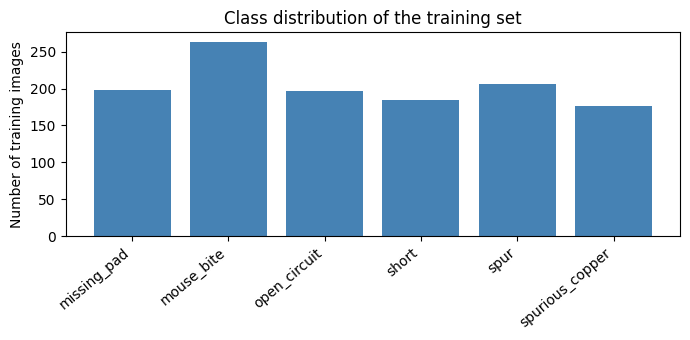

In [6]:
class_counts = []
for name in CLASSES:
    class_counts.append((train_df["label"] == name).sum())
class_counts = np.array(class_counts)

class_weights = len(train_df) / (NUM_CLASSES * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

weight_table = pd.DataFrame({"Class": CLASSES,
                             "Train images": class_counts,
                             "Weight": np.round(class_weights, 3)})
print(weight_table.to_string(index=False))

plt.figure(figsize=(7, 3.5))
plt.bar(CLASSES, class_counts, color="steelblue")
plt.xticks(rotation=40, ha="right")
plt.ylabel("Number of training images")
plt.title("Class distribution of the training set")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "train_class_distribution.png", dpi=100)
plt.show()

# 3. Preprocessing and data augmentation
**Preprocessing (train, validation and test):**
- resize the patch to 128 × 128
- convert to a tensor (values 0 to 1)
- normalise with mean 0.5 and std 0.5 (values become -1 to 1)

**Augmentation (training images only):** random horizontal flip, random vertical flip, random rotation up to 15°, and a small change of brightness / contrast.
These changes keep the defect type the same, but make every epoch look a little different, so the network overfits less.
Validation and test images are **never** augmented.

In [7]:
train_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

eval_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

class PatchDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["path"].tolist()
        self.labels = []
        for name in dataframe["label"]:
            self.labels.append(CLASS_TO_IDX[name])
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)
        return image, self.labels[index]

train_loader = DataLoader(PatchDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(PatchDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(PatchDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Batches per epoch (train / val / test):", len(train_loader), len(val_loader), len(test_loader))

Batches per epoch (train / val / test): 39 8 8


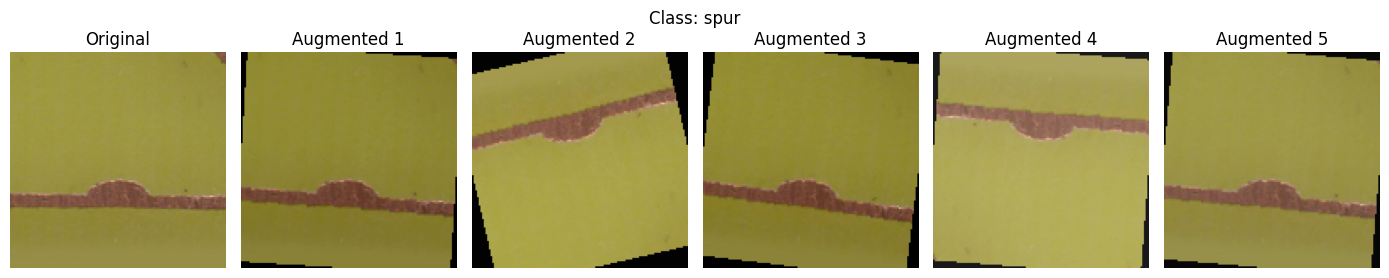

In [8]:
# show one original patch and 5 random augmentations of it
example_path = train_df.iloc[0]["path"]
example_label = train_df.iloc[0]["label"]
example_image = Image.open(example_path).convert("RGB")

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(example_image.resize((INPUT_SIZE, INPUT_SIZE)))
axes[0].set_title("Original")
axes[0].axis("off")
for k in range(1, 6):
    augmented = train_transform(example_image)
    augmented = augmented * 0.5 + 0.5                  # undo the normalisation so we can show it
    augmented = augmented.permute(1, 2, 0).numpy()
    axes[k].imshow(np.clip(augmented, 0, 1))
    axes[k].set_title("Augmented " + str(k))
    axes[k].axis("off")
plt.suptitle("Class: " + example_label)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "augmentation_examples.png", dpi=100)
plt.show()

# 4. Quick look at the data
5 training patches per class.

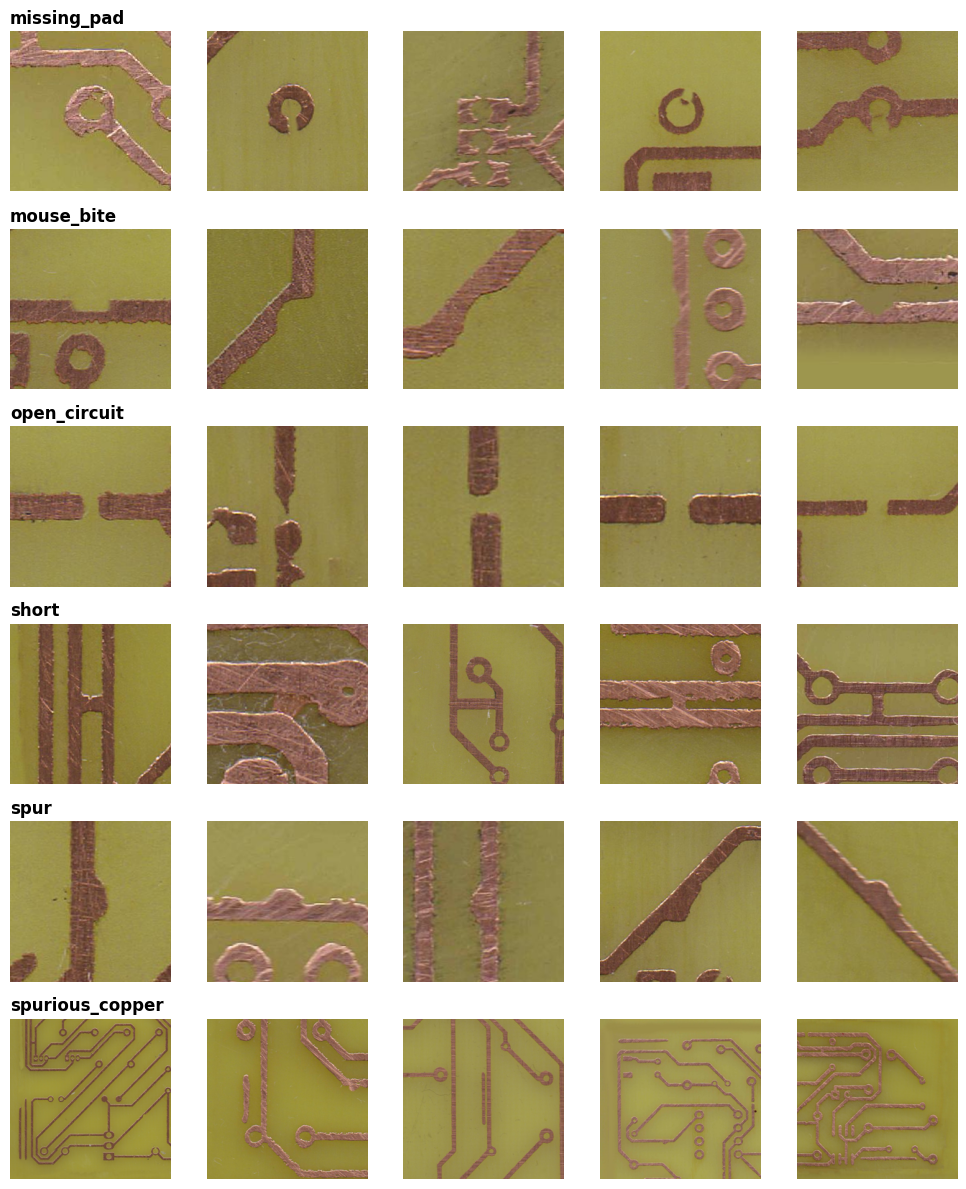

In [9]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(10, 2 * NUM_CLASSES))
for r in range(NUM_CLASSES):
    class_name = CLASSES[r]
    samples = train_df[train_df["label"] == class_name].sample(5, replace=True, random_state=1)
    for k in range(5):
        axes[r, k].imshow(Image.open(samples.iloc[k]["path"]))
        axes[r, k].axis("off")
    axes[r, 0].set_title(class_name, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_patches.png", dpi=100)
plt.show()

# 5. The custom CNN (built from scratch, no pretrained weights)

```
Input 3 x 128 x 128
Block 1:  Conv(3→32)   BN ReLU  Conv(32→32)   BN ReLU  MaxPool   → 32  x 64 x 64
Block 2:  Conv(32→64)  BN ReLU  Conv(64→64)   BN ReLU  MaxPool   → 64  x 32 x 32
Block 3:  Conv(64→128) BN ReLU  Conv(128→128) BN ReLU  MaxPool   → 128 x 16 x 16
Block 4:  Conv(128→256) BN ReLU Conv(256→256) BN ReLU  MaxPool   → 256 x  8 x  8
Global average pooling                                            → 256
Fully connected 256→128, ReLU, Dropout(0.5)
Fully connected 128→6   (one output for each defect class)
```
- **Conv 3×3** layers learn the patterns (edges → shapes → defects). The number of filters doubles after every pooling.
- **BatchNorm** makes training faster and more stable.
- **ReLU** is the activation.
- **MaxPool** halves the image size.
- **Dropout** randomly switches off neurons while training, against overfitting.
- The network ends with a **fully connected layer**.

In [10]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes, dropout):
        super(CustomCNN, self).__init__()

        # ---- Block 1 ----
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # ---- Block 2 ----
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # ---- Block 3 ----
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # ---- Block 4 ----
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # ---- Global average pooling: 256 x 8 x 8  ->  256 ----
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # ---- Fully connected layers ----
        self.fc1 = nn.Linear(256, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)      # flatten
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x


model = CustomCNN(NUM_CLASSES, DROPOUT).to(device)

total_parameters = 0
for p in model.parameters():
    total_parameters = total_parameters + p.numel()
print("Trainable parameters:", total_parameters)

# check the output shape with one fake image
test_input = torch.randn(2, 3, INPUT_SIZE, INPUT_SIZE).to(device)
print("Output shape for 2 images:", tuple(model(test_input).shape), "(2 images x", NUM_CLASSES, "classes)")

Trainable parameters: 1207846
Output shape for 2 images: (2, 6) (2 images x 6 classes)


# 6. Training with early stopping
Every epoch we:
1. train on the training set (with augmentation) and record training loss and accuracy,
2. check the validation set and record validation loss and accuracy,
3. keep a copy of the weights if the validation loss is the best so far,
4. stop if the validation loss has not improved for 10 epochs **and** at least 5 epochs are done.

At the end the weights of the **best epoch** are restored.
Training loss and validation loss are watched together: if training loss keeps falling while validation loss rises, the model is overfitting, and early stopping ends the training.

In [11]:
def validate(model, loader, loss_function):
    """Go through a data loader without training. Returns loss, accuracy, predictions and true labels."""
    model.eval()
    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = loss_function(outputs, labels)
            total_loss = total_loss + loss.item() * len(labels)
            predictions = outputs.argmax(dim=1)
            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    average_loss = total_loss / len(all_labels)
    accuracy = (all_predictions == all_labels).mean()
    return average_loss, accuracy, all_predictions, all_labels

In [12]:
loss_function = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}

best_val_loss = 999999.0
best_epoch = 0
best_weights = None
epochs_without_improvement = 0
stopped_epoch = MAX_EPOCHS

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    # ---------- training ----------
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss = running_loss + loss.item() * len(labels)
        correct = correct + (outputs.argmax(dim=1) == labels).sum().item()
        total = total + len(labels)

    train_loss = running_loss / total
    train_acc = correct / total

    # ---------- validation ----------
    val_loss, val_acc, _, _ = validate(model, val_loader, loss_function)

    # lower the learning rate if the validation loss is stuck
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    # ---------- early stopping logic ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        marker = "  <- best so far"
    else:
        epochs_without_improvement = epochs_without_improvement + 1
        marker = ""

    print("epoch %2d/%d | train loss %.4f acc %.4f | val loss %.4f acc %.4f | lr %.6f%s" %
          (epoch + 1, MAX_EPOCHS, train_loss, train_acc, val_loss, val_acc, current_lr, marker))

    # stop only if at least MIN_EPOCHS epochs are done
    if (epoch + 1) >= MIN_EPOCHS and epochs_without_improvement >= PATIENCE:
        stopped_epoch = epoch + 1
        print()
        print("Early stopping at epoch", stopped_epoch,
              "(validation loss did not improve for", PATIENCE, "epochs)")
        break

train_time = time.time() - start_time
epochs_trained = len(history["train_loss"])

# go back to the best epoch
model.load_state_dict(best_weights)

print()
print("Epochs trained:", epochs_trained)
print("Best epoch:", best_epoch + 1, "| best validation loss: %.4f" % best_val_loss)
print("Training time: %.1f seconds" % train_time)
assert epochs_trained >= MIN_EPOCHS

epoch  1/60 | train loss 1.5949 acc 0.2985 | val loss 2.8156 acc 0.1462 | lr 0.001000  <- best so far
epoch  2/60 | train loss 1.3880 acc 0.3964 | val loss 1.5603 acc 0.3636 | lr 0.001000  <- best so far
epoch  3/60 | train loss 1.2439 acc 0.4347 | val loss 1.1974 acc 0.4743 | lr 0.001000  <- best so far
epoch  4/60 | train loss 1.2352 acc 0.4584 | val loss 1.6418 acc 0.3123 | lr 0.001000
epoch  5/60 | train loss 1.1799 acc 0.4943 | val loss 1.0794 acc 0.4941 | lr 0.001000  <- best so far
epoch  6/60 | train loss 1.1334 acc 0.4902 | val loss 1.1538 acc 0.4980 | lr 0.001000
epoch  7/60 | train loss 1.1048 acc 0.5114 | val loss 1.0563 acc 0.5336 | lr 0.001000  <- best so far
epoch  8/60 | train loss 1.0897 acc 0.5155 | val loss 1.0565 acc 0.5415 | lr 0.001000
epoch  9/60 | train loss 1.0915 acc 0.5163 | val loss 1.0120 acc 0.5652 | lr 0.001000  <- best so far
epoch 10/60 | train loss 1.0887 acc 0.5318 | val loss 1.7027 acc 0.4150 | lr 0.001000
epoch 11/60 | train loss 1.0257 acc 0.5465 |

# 7. Check for overfitting


In [13]:
best_train_acc = history["train_acc"][best_epoch]
best_val_acc = history["val_acc"][best_epoch]
best_train_loss = history["train_loss"][best_epoch]
gap = best_train_acc - best_val_acc

print("At the best epoch (%d):" % (best_epoch + 1))
print("  Train accuracy      : %.4f" % best_train_acc)
print("  Validation accuracy : %.4f" % best_val_acc)
print("  Train loss          : %.4f" % best_train_loss)
print("  Validation loss     : %.4f" % best_val_loss)
print("  Accuracy gap        : %.4f" % gap)
print()
if gap > 0.10:
    print("The gap is large: the model overfits a little. Early stopping returned the best epoch, which limits the damage.")
elif best_train_acc < 0.70 and best_val_acc < 0.70:
    print("Both accuracies are low: the model may be underfitting.")
else:
    print("The gap is small: no strong overfitting.")

At the best epoch (60):
  Train accuracy      : 0.9290
  Validation accuracy : 0.9170
  Train loss          : 0.2277
  Validation loss     : 0.3266
  Accuracy gap        : 0.0120

The gap is small: no strong overfitting.


# 8. Test the final model

In [14]:
# one warm-up pass so the timing is fair (GPU start-up is not counted)
validate(model, test_loader, loss_function)

if device == "cuda":
    torch.cuda.synchronize()
start_time = time.time()
test_loss, test_accuracy, test_predictions, test_labels = validate(model, test_loader, loss_function)
if device == "cuda":
    torch.cuda.synchronize()
test_time = time.time() - start_time
ms_per_image = 1000 * test_time / len(test_labels)

precision, recall, f1, _ = precision_recall_fscore_support(
    test_labels, test_predictions, average="macro", zero_division=0)

label_list = list(range(NUM_CLASSES))
cm = confusion_matrix(test_labels, test_predictions, labels=label_list)
report = classification_report(test_labels, test_predictions, labels=label_list,
                               target_names=CLASSES, digits=3, zero_division=0)

print("Test loss     : %.4f" % test_loss)
print("Accuracy      : %.4f" % test_accuracy)
print("Precision     : %.4f (macro)" % precision)
print("Recall        : %.4f (macro)" % recall)
print("F1-score      : %.4f (macro)" % f1)
print("Training time : %.1f seconds" % train_time)
print("Testing time  : %.3f seconds (%.2f ms per image)" % (test_time, ms_per_image))

Test loss     : 0.2164
Accuracy      : 0.9378
Precision     : 0.9432 (macro)
Recall        : 0.9451 (macro)
F1-score      : 0.9433 (macro)
Training time : 364.6 seconds
Testing time  : 0.706 seconds (3.14 ms per image)


# 9. Results

### 9.1 Accuracy curve (train vs validation)

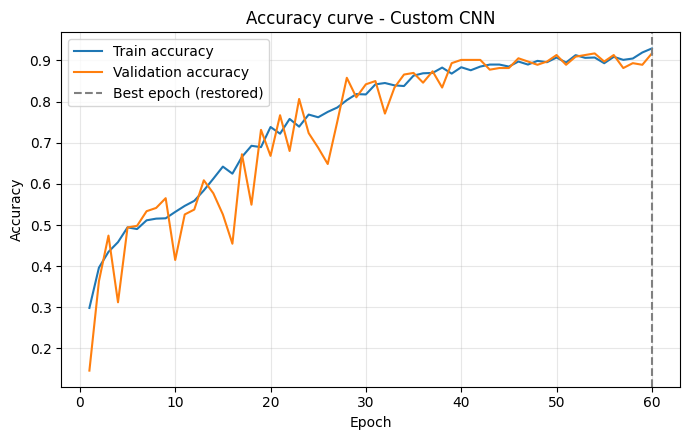

In [15]:
epochs = range(1, epochs_trained + 1)

plt.figure(figsize=(7, 4.5))
plt.plot(epochs, history["train_acc"], label="Train accuracy")
plt.plot(epochs, history["val_acc"], label="Validation accuracy")
plt.axvline(best_epoch + 1, color="grey", linestyle="--", label="Best epoch (restored)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy curve - Custom CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_curve.png", dpi=100)
plt.show()

### 9.2 Loss curve (train vs validation)

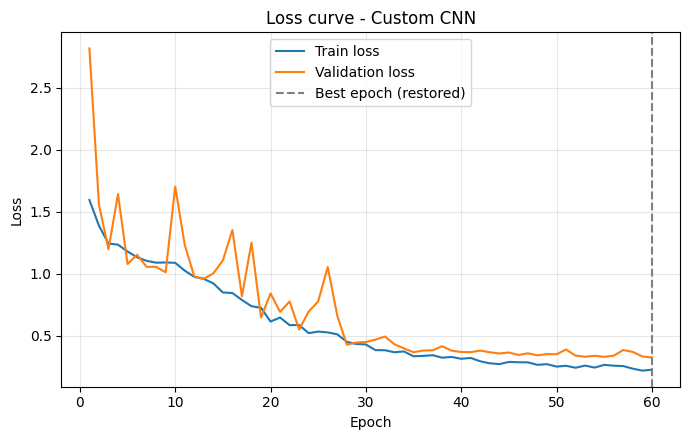

In [16]:
plt.figure(figsize=(7, 4.5))
plt.plot(epochs, history["train_loss"], label="Train loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.axvline(best_epoch + 1, color="grey", linestyle="--", label="Best epoch (restored)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss curve - Custom CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=100)
plt.show()

### 9.3 Confusion matrix (test set)

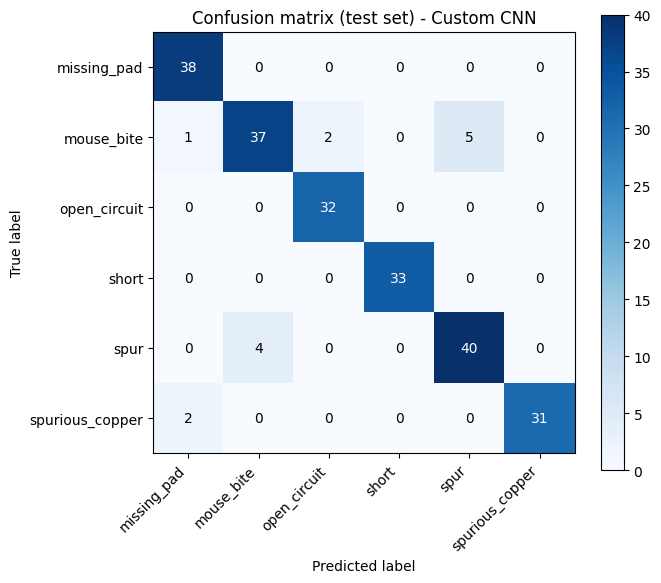

In [17]:
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), CLASSES, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), CLASSES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j] > cm.max() / 2:
            text_color = "white"
        else:
            text_color = "black"
        plt.text(j, i, cm[i, j], ha="center", va="center", color=text_color)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion matrix (test set) - Custom CNN")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=100)
plt.show()

### 9.4 Classification report (precision, recall, F1 per class)

In [18]:
print(report)

with open(RESULTS_DIR / "classification_report.txt", "w") as f:
    f.write(report)

                 precision    recall  f1-score   support

    missing_pad      0.927     1.000     0.962        38
     mouse_bite      0.902     0.822     0.860        45
   open_circuit      0.941     1.000     0.970        32
          short      1.000     1.000     1.000        33
           spur      0.889     0.909     0.899        44
spurious_copper      1.000     0.939     0.969        33

       accuracy                          0.938       225
      macro avg      0.943     0.945     0.943       225
   weighted avg      0.938     0.938     0.937       225



### 9.5 Summary table

In [19]:
summary = pd.DataFrame([{
    "Model": "Custom CNN (from scratch)",
    "Parameters": total_parameters,
    "Epochs trained": epochs_trained,
    "Best epoch": best_epoch + 1,
    "Accuracy": round(test_accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1-score": round(f1, 4),
    "Training time (s)": round(train_time, 1),
    "Testing time (s)": round(test_time, 3),
    "ms per image": round(ms_per_image, 2),
}])
summary.to_csv(RESULTS_DIR / "summary_table.csv", index=False)
summary.T

,0
Model,Custom CNN (from scratch)
Parameters,1207846
Epochs trained,60
Best epoch,60
Accuracy,0.9378
Precision,0.9432
Recall,0.9451
F1-score,0.9433
Training time (s),364.6
Testing time (s),0.706


### 9.6 Optional: custom CNN vs pretrained models (Submission 2)

In [20]:
# Example: submission2_results = {"resnet50 fine_tuning": {"Accuracy": 0.95, "F1-score": 0.95, "Training time (s)": 300}}
submission2_results = None

if submission2_results is None:
    print("Skipped (no Submission 2 numbers were typed in).")
else:
    rows = []
    for name in submission2_results:
        row = {"Model": name}
        row.update(submission2_results[name])
        rows.append(row)
    rows.append({"Model": "Custom CNN (from scratch)", "Accuracy": round(test_accuracy, 4),
                 "F1-score": round(f1, 4), "Training time (s)": round(train_time, 1)})
    comparison = pd.DataFrame(rows)
    comparison.to_csv(RESULTS_DIR / "comparison_with_submission2.csv", index=False)
    display(comparison)

Skipped (no Submission 2 numbers were typed in).


# 10. Conclusion
- A custom CNN with **4 blocks of convolution + BatchNorm + ReLU + max-pooling**, global average pooling and **fully connected layers** was trained **from scratch** on the PCB defect patches.
- Preprocessing (resize, normalisation) and **data augmentation** (flips, rotation, brightness/contrast) were used on the training set; **class weights** handle unequal class sizes.
- All hyperparameters were set once (Adam, learning rate 0.001, batch size 32, dropout 0.5) and never changed.
- Training and validation loss were monitored every epoch. **Early stopping** (patience 10, minimum 5 epochs) ended training and the weights of the best epoch were restored.
- Accuracy, precision, recall, F1, confusion matrix, per-class classification report, training time and testing time are reported, as in Submission 2.
- A model trained from scratch usually scores a little lower than a pretrained model and needs more epochs, but it is much smaller and faster at test time. The summary table shows the real numbers for our run.
- The test set is small, so differences of 1–2 points can be noise. These results measure defect-type recognition on cropped patches, not full-board defect detection.
- The saved file `custom_cnn_best.pt` is the **baseline** for Submission 4 (adding one attention module).

# 11. Download the results


In [21]:
# save the trained weights (baseline for Submission 4)
torch.save(model.state_dict(), RESULTS_DIR / "custom_cnn_best.pt")

# save the training history
history_table = pd.DataFrame(history)
history_table.insert(0, "epoch", range(1, epochs_trained + 1))
history_table.to_csv(RESULTS_DIR / "training_history.csv", index=False)

shutil.make_archive("submission3_results", "zip", RESULTS_DIR)
print("Created submission3_results.zip")

try:
    from google.colab import files
    files.download("submission3_results.zip")
except Exception as e:
    print("Download works only inside Google Colab. The file is saved as submission3_results.zip:", e)

Created submission3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>